<a href="https://colab.research.google.com/github/RusdiansyahAlief19/BSARec_Reproduce/blob/main/notebooks/BSARec_Reproduce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reproduksi BSARec (Beauty) + W&B
Urutan: **A** setup → **B** baseline tanpa W&B (hasil sudah ada, jangan dijalankan ulang) → **C** login W&B + patch `main.py` → **D** run dengan W&B.
Di sesi Colab baru, jalankan A lalu langsung C (B dilewati).

## A. Setup

In [5]:
%cd /content
![ -d BSARec ] || git clone https://github.com/yehjin-shin/BSARec.git
%cd /content/BSARec/src
!pip install -q scipy tqdm wandb

/content
Cloning into 'BSARec'...
remote: Enumerating objects: 592, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 592 (delta 28), reused 20 (delta 20), pack-reused 549 (from 1)
Receiving objects: 100% (592/592), 859.10 MiB | 22.94 MiB/s, done.
Resolving deltas: 100% (136/136), done.
Updating files: 100% (384/384), done.
/content/BSARec/src


## B. Baseline tanpa W&B (`main.py` asli)
Sel di bagian ini sudah dijalankan dan outputnya disimpan sebagai bukti hasil reproduksi. **Jangan dijalankan ulang** (training sekitar 12-20 menit per run). Nilai test akhir:
- Eval checkpoint penulis (`BSARec_Beauty_best`): HR@5 0.0736, NDCG@5 0.0523, HR@10 0.1008, NDCG@10 0.0611, HR@20 0.1373, NDCG@20 0.0703 (sama dengan Table 2 paper)
- BSARec Beauty (seed 42): HR@5 0.0702, NDCG@5 0.0500, HR@10 0.0988, NDCG@10 0.0592, HR@20 0.1347, NDCG@20 0.0683
- SASRec Beauty (seed 42): HR@5 0.0302, NDCG@5 0.0192, HR@10 0.0503, NDCG@10 0.0256, HR@20 0.0800, NDCG@20 0.0331
(Label `Epoch: 0` di log hanya placeholder dari `trainer.test(0)`.)

In [6]:
!python main.py --data_name Beauty --alpha 0.7 --c 5 --num_attention_heads 1 --load_model BSARec_Beauty_best --do_eval

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-27 01:51:23,045 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=True, load_model='BSARec_Beauty_best', train_name='Oct-27-2026_01-51-20', num_items=10, num_users=22364, lr=0.001, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_pro

In [ ]:
!python main.py --data_name Beauty --lr 0.0005 --alpha 0.7 --c 5 --num_attention_heads 1 --train_name BSARec_Beauty

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-24 02:28:50,676 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='BSARec_Beauty', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, 

In [ ]:
!python main.py --data_name Beauty --model_type SASRec --lr 0.0005 --num_attention_heads 1 --train_name SASRec_Beauty

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-24 02:53:23,532 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='SASRec_Beauty', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='SASRec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, 

## C. Login W&B dan patch `main.py`
API key diketik di kotak tersembunyi, tidak disimpan di notebook. Buat key di Forge → User settings → API keys. Jangan tempel key ke sel mana pun atau ke chat.

In [7]:
import os, getpass, wandb

os.environ.pop("WANDB_API_KEY", None)          # buang key lama kalau masih tersangkut di sesi
key = getpass.getpass("W&B API key: ").strip()
print("panjang key:", len(key))                # cek panjang saja (sekitar 86), bukan isinya
wandb.login(key=key, relogin=True)
del key

W&B API key: ··········
panjang key: 86


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rusdiasputre (rusdiasputre-brawijaya-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [8]:
# Backup main.py asli sekali saja (tidak menimpa backup kalau sel ini diulang)
![ -f main_backup.py ] || cp main.py main_backup.py

In [9]:
%%writefile main.py
import os
import torch
import numpy as np
import wandb

from model import MODEL_DICT
from trainers import Trainer
from utils import EarlyStopping, check_path, set_seed, parse_args, set_logger
from dataset import get_seq_dic, get_dataloder, get_rating_matrix

def main():

    args = parse_args()
    log_path = os.path.join(args.output_dir, args.train_name + '.log')
    logger = set_logger(log_path)

    set_seed(args.seed)
    check_path(args.output_dir)

    os.environ["CUDA_VISIBLE_DEVICES"] = args.gpu_id
    args.cuda_condition = torch.cuda.is_available() and not args.no_cuda

    seq_dic, max_item, num_users = get_seq_dic(args)
    args.item_size = max_item + 1
    args.num_users = num_users + 1

    args.checkpoint_path = os.path.join(args.output_dir, args.train_name + '.pt')
    args.same_target_path = os.path.join(args.data_dir, args.data_name+'_same_target.npy')
    train_dataloader, eval_dataloader, test_dataloader = get_dataloder(args,seq_dic)

    logger.info(str(args))
    model = MODEL_DICT[args.model_type.lower()](args=args)
    logger.info(model)
    trainer = Trainer(model, train_dataloader, eval_dataloader, test_dataloader, args, logger)

    args.valid_rating_matrix, args.test_rating_matrix = get_rating_matrix(args.data_name, seq_dic, max_item)

    if args.do_eval:
        if args.load_model is None:
            logger.info(f"No model input!")
            exit(0)
        else:
            args.checkpoint_path = os.path.join(args.output_dir, args.load_model + '.pt')
            trainer.load(args.checkpoint_path)

            logger.info(f"Load model from {args.checkpoint_path} for test!")
            scores, result_info = trainer.test(0)
            args.checkpoint_path = os.path.join(args.output_dir, args.train_name + '.pt')

    else:
        # Mengambil konfigurasi hyperparameter untuk dicatat di W&B dashboard
        cfg = {k: v for k, v in vars(args).items() if isinstance(v, (int, float, str, bool))}
        wandb.init(project="bsarec-repro", name=args.train_name, config=cfg)

        early_stopping = EarlyStopping(args.checkpoint_path, logger=logger, patience=args.patience, verbose=True)
        for epoch in range(args.epochs):

            trainer.train(epoch)
            scores, _ = trainer.valid(epoch)

            # Log validasi epoch ke W&B
            wandb.log({
                "epoch": epoch,
                "valid/HR@5": scores[0], "valid/NDCG@5": scores[1],
                "valid/HR@10": scores[2], "valid/NDCG@10": scores[3],
                "valid/HR@20": scores[4], "valid/NDCG@20": scores[5]
            })

            # Evaluate on MRR (menggunakan metrik evaluasi terakhir di list scores)
            early_stopping(np.array(scores[-1:]), trainer.model)
            if early_stopping.early_stop:
                logger.info("Early stopping")
                break

        logger.info("---------------Test Score---------------")
        trainer.model.load_state_dict(torch.load(args.checkpoint_path))
        scores, result_info = trainer.test(0)

        # Log hasil test final ke W&B
        wandb.log({
            "test/HR@5": scores[0], "test/NDCG@5": scores[1],
            "test/HR@10": scores[2], "test/NDCG@10": scores[3],
            "test/HR@20": scores[4], "test/NDCG@20": scores[5]
        })
        wandb.finish()

    logger.info(args.train_name)
    logger.info(result_info)

if __name__ == '__main__':
    main()

Overwriting main.py


## D. Run dengan W&B
Jalankan sel tes pendek dulu, cek kurva muncul di dashboard W&B, baru run penuh.
Nama run dibuat unik (`_s43`) supaya tidak menimpa `.pt`/`.log` baseline di folder `output/`. Untuk seed berikutnya ganti `43` jadi `44` di `--seed` dan `--train_name`.

In [ ]:
!python main.py --data_name Beauty --model_type SASRec --lr 0.0005 --num_attention_heads 1 --epochs 2 --train_name wandb_test

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-24 03:09:52,866 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='wandb_test', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=2, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='SASRec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidde

In [ ]:
!python main.py --data_name Beauty --lr 0.0005 --alpha 0.7 --c 5 --num_attention_heads 1 --seed 43 --train_name BSARec_Beauty_s43

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-24 03:10:46,522 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='BSARec_Beauty_s43', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=43, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0

In [ ]:
!python main.py --data_name Beauty --model_type SASRec --lr 0.0005 --num_attention_heads 1 --seed 43 --train_name SASRec_Beauty_s43

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-24 03:30:37,192 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='SASRec_Beauty_s43', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=43, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='SASRec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0

In [3]:
!ls /content/BSARec/src/main.py

ls: cannot access '/content/BSARec/src/main.py': No such file or directory


In [10]:
!python main.py --data_name Beauty --model_type SASRec --lr 0.0005 --num_attention_heads 1 --seed 44 --train_name SASRec_Beauty_s44

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-27 01:55:37,952 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='SASRec_Beauty_s44', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=44, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='SASRec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0

In [13]:
# Sel Colab: bandingkan hasil reproduksi Beauty (3 seed) dengan Table 2 paper
# Semua angka diketik manual, tidak butuh file. Ganti SELURUH isi sel perbandingan lama dengan ini.
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

KEYS = ["HR@5", "NDCG@5", "HR@10", "NDCG@10", "HR@20", "NDCG@20"]

paper = {  # Table 2 paper, Beauty
    "BSARec": [0.0736, 0.0523, 0.1008, 0.0611, 0.1373, 0.0703],
    "SASRec": [0.0340, 0.0221, 0.0531, 0.0283, 0.0823, 0.0356],
}
hasilku = {  # hasil test akhir per seed (urutan: HR@5, NDCG@5, HR@10, NDCG@10, HR@20, NDCG@20)
    "BSARec": {"s42": [0.0702, 0.0499, 0.0988, 0.0592, 0.1347, 0.0683],
               "s43": [0.0709, 0.0507, 0.0994, 0.0599, 0.1334, 0.0684],
               "s44": [0.0698, 0.0498, 0.0957, 0.0581, 0.1322, 0.0673]},
    "SASRec": {"s42": [0.0302, 0.0192, 0.0503, 0.0256, 0.0800, 0.0331],
               "s43": [0.0350, 0.0222, 0.0542, 0.0284, 0.0823, 0.0355],
               "s44": [0.0370, 0.0241, 0.0554, 0.0300, 0.0846, 0.0373]},
}

hasil = {}
for model in paper:
    df = pd.DataFrame(hasilku[model], index=KEYS)
    seeds = list(df.columns)
    df.insert(0, "Paper", paper[model])
    df["Mean"] = df[seeds].mean(axis=1)
    df["Std"] = df[seeds].std(axis=1)
    for s in seeds:
        df[f"Gap {s} (%)"] = (df[s] - df["Paper"]) / df["Paper"] * 100
    df["Gap Mean (%)"] = (df["Mean"] - df["Paper"]) / df["Paper"] * 100
    hasil[model] = df
    print(f"\n=== {model} (Beauty), {len(seeds)} seed: {', '.join(seeds)} ===")
    print(df.round(4).to_string())

# Perbandingan keseluruhan: seberapa besar BSARec mengungguli SASRec (paper vs reproduksiku)
b, s = hasil["BSARec"], hasil["SASRec"]
ringkas = pd.DataFrame({
    "BSARec paper": b["Paper"], "BSARec mean": b["Mean"],
    "SASRec paper": s["Paper"], "SASRec mean": s["Mean"],
    "Naik vs SASRec, paper (%)": (b["Paper"] / s["Paper"] - 1) * 100,
    "Naik vs SASRec, aku (%)": (b["Mean"] / s["Mean"] - 1) * 100,
})
print("\n=== Ringkasan: BSARec vs SASRec ===")
print(ringkas.round(4).to_string())


=== BSARec (Beauty), 3 seed: s42, s43, s44 ===
          Paper     s42     s43     s44    Mean     Std  Gap s42 (%)  Gap s43 (%)  Gap s44 (%)  Gap Mean (%)
HR@5     0.0736  0.0702  0.0709  0.0698  0.0703  0.0006      -4.6196      -3.6685      -5.1630       -4.4837
NDCG@5   0.0523  0.0499  0.0507  0.0498  0.0501  0.0005      -4.5889      -3.0593      -4.7801       -4.1428
HR@10    0.1008  0.0988  0.0994  0.0957  0.0980  0.0020      -1.9841      -1.3889      -5.0595       -2.8108
NDCG@10  0.0611  0.0592  0.0599  0.0581  0.0591  0.0009      -3.1097      -1.9640      -4.9100       -3.3279
HR@20    0.1373  0.1347  0.1334  0.1322  0.1334  0.0013      -1.8937      -2.8405      -3.7145       -2.8162
NDCG@20  0.0703  0.0683  0.0684  0.0673  0.0680  0.0006      -2.8450      -2.7027      -4.2674       -3.2717

=== SASRec (Beauty), 3 seed: s42, s43, s44 ===
          Paper     s42     s43     s44    Mean     Std  Gap s42 (%)  Gap s43 (%)  Gap s44 (%)  Gap Mean (%)
HR@5     0.0340  0.0302  0.0350 

In [14]:
# Sel 1: sweep alpha (c=5 tetap)
for a in [0.1, 0.3, 0.5, 0.9]:
    !python main.py --data_name Beauty --lr 0.0005 --alpha {a} --c 5 --num_attention_heads 1 --seed 42 --train_name BSARec_Beauty_a{a}_c5

# Sel 2: sweep c (alpha=0.7 tetap)
for c in [1, 3, 7, 9]:
    !python main.py --data_name Beauty --lr 0.0005 --alpha 0.7 --c {c} --num_attention_heads 1 --seed 42 --train_name BSARec_Beauty_a0.7_c{c}

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-27 02:51:43,790 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='BSARec_Beauty_a0.1_c5', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_pr

In [15]:
!for f in output/BSARec_Beauty_a*.log; do echo $f; grep "'HR@5'" $f | tail -1; done

output/BSARec_Beauty_a0.1_c5.log
2026-10-27 03:07:34,894 - {'Epoch': 0, 'HR@5': '0.0700', 'NDCG@5': '0.0494', 'HR@10': '0.0955', 'NDCG@10': '0.0576', 'HR@20': '0.1308', 'NDCG@20': '0.0665'}
output/BSARec_Beauty_a0.3_c5.log
2026-10-27 03:26:00,242 - {'Epoch': 0, 'HR@5': '0.0708', 'NDCG@5': '0.0497', 'HR@10': '0.0958', 'NDCG@10': '0.0578', 'HR@20': '0.1335', 'NDCG@20': '0.0673'}
output/BSARec_Beauty_a0.5_c5.log
2026-10-27 03:45:11,013 - {'Epoch': 0, 'HR@5': '0.0706', 'NDCG@5': '0.0501', 'HR@10': '0.0985', 'NDCG@10': '0.0591', 'HR@20': '0.1339', 'NDCG@20': '0.0680'}
output/BSARec_Beauty_a0.7_c1.log
2026-10-27 04:19:18,078 - {'Epoch': 0, 'HR@5': '0.0681', 'NDCG@5': '0.0486', 'HR@10': '0.0945', 'NDCG@10': '0.0571', 'HR@20': '0.1285', 'NDCG@20': '0.0656'}
output/BSARec_Beauty_a0.7_c3.log
2026-10-27 04:31:57,723 - {'Epoch': 0, 'HR@5': '0.0694', 'NDCG@5': '0.0497', 'HR@10': '0.0967', 'NDCG@10': '0.0585', 'HR@20': '0.1316', 'NDCG@20': '0.0673'}
output/BSARec_Beauty_a0.7_c7.log
2026-10-27 04:50:

               HR@5  NDCG@5   HR@10  NDCG@10   HR@20  NDCG@20  Gap HR@20 vs base (%)  Gap NDCG@20 vs base (%)  HR@20 beda > 1 std?
alpha (c=5)                                                                                                                       
0.1          0.0700  0.0494  0.0955   0.0576  0.1308   0.0665                -2.8953                  -2.6354                 True
0.3          0.0708  0.0497  0.0958   0.0578  0.1335   0.0673                -0.8909                  -1.4641                False
0.5          0.0706  0.0501  0.0985   0.0591  0.1339   0.0680                -0.5939                  -0.4392                False
0.7          0.0702  0.0499  0.0988   0.0592  0.1347   0.0683                 0.0000                   0.0000                False
0.9          0.0709  0.0501  0.0989   0.0590  0.1348   0.0681                 0.0742                  -0.2928                False 

                 HR@5  NDCG@5   HR@10  NDCG@10   HR@20  NDCG@20  Gap HR@20 vs bas

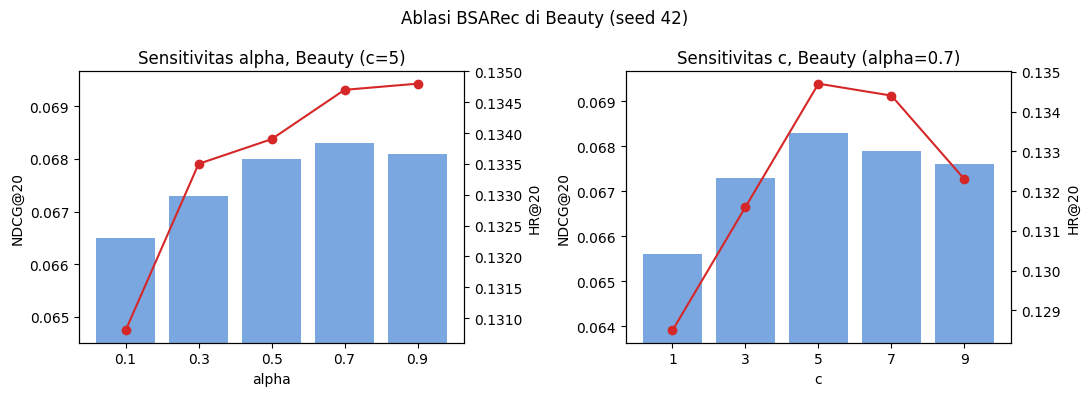

In [16]:
# Sel Colab: tabel + grafik ablasi alpha dan c di Beauty (seed 42). Semua angka diketik manual.
import pandas as pd
import matplotlib.pyplot as plt

KEYS = ["HR@5", "NDCG@5", "HR@10", "NDCG@10", "HR@20", "NDCG@20"]

# urutan: HR@5, NDCG@5, HR@10, NDCG@10, HR@20, NDCG@20
alpha = {  # c = 5 tetap
    0.1: [0.0700, 0.0494, 0.0955, 0.0576, 0.1308, 0.0665],
    0.3: [0.0708, 0.0497, 0.0958, 0.0578, 0.1335, 0.0673],
    0.5: [0.0706, 0.0501, 0.0985, 0.0591, 0.1339, 0.0680],
    0.7: [0.0702, 0.0499, 0.0988, 0.0592, 0.1347, 0.0683],  # baseline seed 42
    0.9: [0.0709, 0.0501, 0.0989, 0.0590, 0.1348, 0.0681],
}
c_val = {  # alpha = 0.7 tetap
    1: [0.0681, 0.0486, 0.0945, 0.0571, 0.1285, 0.0656],
    3: [0.0694, 0.0497, 0.0967, 0.0585, 0.1316, 0.0673],
    5: [0.0702, 0.0499, 0.0988, 0.0592, 0.1347, 0.0683],  # baseline seed 42
    7: [0.0707, 0.0498, 0.0986, 0.0589, 0.1344, 0.0679],
    9: [0.0701, 0.0500, 0.0974, 0.0588, 0.1323, 0.0676],
}
BASE = alpha[0.7]
NOISE = 0.0013  # std HR@20 BSARec antar 3 seed (42, 43, 44)

def tabel(d, nama):
    df = pd.DataFrame(d, index=KEYS).T
    df.index.name = nama
    df["Gap HR@20 vs base (%)"] = (df["HR@20"] / BASE[4] - 1) * 100
    df["Gap NDCG@20 vs base (%)"] = (df["NDCG@20"] / BASE[5] - 1) * 100
    df["HR@20 beda > 1 std?"] = (df["HR@20"] - BASE[4]).abs() > NOISE
    return df

ta, tc = tabel(alpha, "alpha (c=5)"), tabel(c_val, "c (alpha=0.7)")
print(ta.round(4).to_string(), "\n")
print(tc.round(4).to_string())
print(f"\nCatatan: 1 seed per titik; selisih HR@20 di bawah ~{NOISE} (1 std antar seed) tidak bisa dibedakan dari noise; di atas {2*NOISE:.4f} (2 std) lebih meyakinkan.")

def panel(ax, df, xlabel, judul):
    x = range(len(df))
    ax.bar(x, df["NDCG@20"], color="#7aa7e0", label="NDCG@20")
    ax.set_ylim(df["NDCG@20"].min() * 0.97, df["NDCG@20"].max() * 1.02)
    ax.set_ylabel("NDCG@20"); ax.set_xlabel(xlabel); ax.set_title(judul)
    ax.set_xticks(list(x)); ax.set_xticklabels(df.index)
    ax2 = ax.twinx()
    ax2.plot(list(x), df["HR@20"], "o-", color="#d62728", label="HR@20")
    ax2.set_ylabel("HR@20")
    return ax, ax2

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
panel(axs[0], ta, "alpha", "Sensitivitas alpha, Beauty (c=5)")
panel(axs[1], tc, "c", "Sensitivitas c, Beauty (alpha=0.7)")
fig.suptitle("Ablasi BSARec di Beauty (seed 42)")
plt.tight_layout()
plt.savefig("ablasi_beauty.png", dpi=150)
plt.show()

In [17]:
   from google.colab import drive
   drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
   !mkdir -p /content/drive/MyDrive/BSARec_backup
   !cp -r output /content/drive/MyDrive/BSARec_backup/
   !cp -r wandb /content/drive/MyDrive/BSARec_backup/
   !ls /content/drive/MyDrive/BSARec_backup/output

BSARec_Beauty_a0.1_c5.log  BSARec_Beauty_a0.7_c3.pt   BSARec_Beauty_s44.log
BSARec_Beauty_a0.1_c5.pt   BSARec_Beauty_a0.7_c7.log  BSARec_Beauty_s44.pt
BSARec_Beauty_a0.3_c5.log  BSARec_Beauty_a0.7_c7.pt   BSARec_LastFM_best.log
BSARec_Beauty_a0.3_c5.pt   BSARec_Beauty_a0.7_c9.log  BSARec_LastFM_best.pt
BSARec_Beauty_a0.5_c5.log  BSARec_Beauty_a0.7_c9.pt   Oct-27-2026_01-51-20.log
BSARec_Beauty_a0.5_c5.pt   BSARec_Beauty_a0.9_c5.log  SASRec_Beauty_s44.log
BSARec_Beauty_a0.7_c1.log  BSARec_Beauty_a0.9_c5.pt   SASRec_Beauty_s44.pt
BSARec_Beauty_a0.7_c1.pt   BSARec_Beauty_best.log
BSARec_Beauty_a0.7_c3.log  BSARec_Beauty_best.pt


In [19]:
   import sys, torch
   print(sys.version)
   print("torch:", torch.__version__, "| CUDA:", torch.version.cuda)
   print("GPU:", torch.cuda.get_device_name(0))
   !pip list 2>/dev/null | grep -i -E "numpy|scipy|tqdm|wandb"

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch: 2.11.0+cu130 | CUDA: 13.0
GPU: Tesla T4
numpy                                 2.1.3
scipy                                 1.16.3
tqdm                                  4.67.3
wandb                                 0.28.1


In [20]:
!python main.py --data_name Beauty --lr 0.0005 --alpha 0.7 --c 5 --num_attention_heads 1 --seed 42 --train_name BSARec_Beauty_s42

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
2026-10-27 05:56:55,750 - Namespace(data_dir='./data/', output_dir='output/', data_name='Beauty', do_eval=False, load_model=None, train_name='BSARec_Beauty_s42', num_items=10, num_users=22364, lr=0.0005, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=4, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0

In [25]:
%cd /content
from google.colab import files
uploaded = files.upload()   # klik "Choose Files", pilih zip-nya
!ls

/content


Saving BSARec_Reproduce_repo.zip to BSARec_Reproduce_repo (1).zip
 BSARec				  BSARec_Reproduce_repo.zip   sample_data
'BSARec_Reproduce_repo (1).zip'   drive


In [26]:
!unzip -q "BSARec_Reproduce_repo.zip" -d /content
!ls /content/BSARec_Reproduce

figures  logs  notebooks  patches  README.md  results  scripts


In [33]:
from google.colab import userdata
try:
    t = userdata.get('GITHUB_TOKEN')
    print("ada, panjang:", len(t), "| awal:", t[:11])
except Exception as e:
    print(type(e).__name__, "-", e)

ada, panjang: 93 | awal: github_pat_


In [35]:
from google.colab import userdata
token = userdata.get('GITHUB_TOKEN')
!git config --global user.name "RusdiansyahAlief19"
!git config --global user.email "rusdiasputre@gmail.com"
%cd /content/BSARec_Reproduce
!git init -b main
!git add .
!git status --short

/content/BSARec_Reproduce
Initialized empty Git repository in /content/BSARec_Reproduce/.git/
A  .gitignore
A  README.md
A  figures/ablasi_beauty.png
A  logs/BSARec_Beauty_a0.1_c5.log
A  logs/BSARec_Beauty_a0.3_c5.log
A  logs/BSARec_Beauty_a0.5_c5.log
A  logs/BSARec_Beauty_a0.7_c1.log
A  logs/BSARec_Beauty_a0.7_c3.log
A  logs/BSARec_Beauty_a0.7_c7.log
A  logs/BSARec_Beauty_a0.7_c9.log
A  logs/BSARec_Beauty_a0.9_c5.log
A  logs/BSARec_Beauty_best.log
A  logs/BSARec_Beauty_s42.log
A  logs/BSARec_Beauty_s44.log
A  logs/BSARec_LastFM_best.log
A  logs/Oct-27-2026_01-51-20.log
A  logs/README.md
A  logs/SASRec_Beauty_s44.log
A  notebooks/README.md
A  patches/README.md
A  patches/wandb_logging.patch
A  results/ablation_alpha_beauty.csv
A  results/ablation_c_beauty.csv
A  results/bsarec_beauty_3seeds.csv
A  results/sasrec_beauty_3seeds.csv
A  scripts/compare_with_paper.py
A  scripts/plot_ablation.py
A  scripts/run_ablation.sh
A  scripts/run_baselines.sh


In [36]:
!git commit -m "Tambah hasil reproduksi BSARec di Beauty: skrip, hasil, log, grafik"
!git remote add origin https://{token}@github.com/RusdiansyahAlief19/BSARec_Reproduce.git
!git push -u origin main
!git remote remove origin

[main (root-commit) 29ad3d0] Tambah hasil reproduksi BSARec di Beauty: skrip, hasil, log, grafik
 29 files changed, 3070 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 figures/ablasi_beauty.png
 create mode 100644 logs/BSARec_Beauty_a0.1_c5.log
 create mode 100644 logs/BSARec_Beauty_a0.3_c5.log
 create mode 100644 logs/BSARec_Beauty_a0.5_c5.log
 create mode 100644 logs/BSARec_Beauty_a0.7_c1.log
 create mode 100644 logs/BSARec_Beauty_a0.7_c3.log
 create mode 100644 logs/BSARec_Beauty_a0.7_c7.log
 create mode 100644 logs/BSARec_Beauty_a0.7_c9.log
 create mode 100644 logs/BSARec_Beauty_a0.9_c5.log
 create mode 100644 logs/BSARec_Beauty_best.log
 create mode 100644 logs/BSARec_Beauty_s42.log
 create mode 100644 logs/BSARec_Beauty_s44.log
 create mode 100644 logs/BSARec_LastFM_best.log
 create mode 100644 logs/Oct-27-2026_01-51-20.log
 create mode 100644 logs/README.md
 create mode 100644 logs/SASRec_Beauty_s44.log
 create mode 100644 notebook